# Notebook 23: Arquitectura Estructural de Trampas de Dilatación y Reentrenamiento Multigeofísico-Estructural

## 1. Fundamento Geocientífico: La Estructura como Trampa de Dilatación y Permeabilidad
En los sistemas minerales auríferos hidrotermales (orogénicos, tipo intrusion-related / IRGS y epitermales), el oro **no se acumula de forma continua ni homogénea a lo largo de las grandes fallas maestras**. Las fallas principales de primer orden suelen actuar como conductos regionales de alta velocidad de escape de fluidos o permanecer selladas bajo compresión.

La precipitación masiva de cuarzo y metales preciosos ocurre preferentemente en **trampas estructurales de dilatación**:
1. **Zonas de Confluencia e Intersección Estructural (*Dilational Jogs* / Nodos de Dilatación):**
   Intersecciones entre fallas de desgarre y frentes de cabalgamiento, donde el cizallamiento y la refracción de esfuerzos generan descompresión adiabática brusca (*flash vaporization* / ebullición), desestabilizando los complejos bisulfurados de oro ($\text{Au(HS)}_2^-$) y precipitando oro nativo.
2. **Densidad de Fracturación Local ($1\text{ km}$):**
   Concentración de fracturas secundarias y terciarias que aumentan exponencialmente la permeabilidad y porosidad secundaria de la roca encajante.
3. **Trampa Dilatacional Reológica:**
   Acoplamiento físico entre la densidad de fracturas y los límites mecánicos de competencia litológica (cuarcitas rígidas vs. pizarras dúctiles), donde la fracturación frágil se magnifica en la unidad competente.
4. **Acoplamiento Cortical Profundo - Superficie:**
   Intersección entre los grandes gradientes gravimétricos corticales profundos (suturas) y las fallas cartografiadas en superficie.

---

## 2. Objetivos de este Notebook
1. Derivar las **4 variables cuantitativas de arquitectura de dilatación estructural**.
2. Analizar la firma estructural de los yacimientos auríferos catalogados frente al fondo peninsular.
3. Reentrenar el ensamble nacional LightGBM de 8 miembros incorporando el espacio completo de **79 covariables multigeofísicas y estructurales**, con regularización `colsample_bytree = 0.7` y `min_child_samples = 15`.
4. Evaluar el impacto en la malla nacional completa (*in-sample*) y en las **7 rotaciones territoriales ciegas** (*out-of-fold*).

In [1]:
import json
import math
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
import lightgbm as lgb

from geoau.geochemical_experiment import load_data, make_preprocessor, predict, select_sample
from geoau.national_evaluation import deposit_metrics, PERCENTAGES

ROOT = Path("..").resolve() if Path("..").resolve().name == "GeoAI" and not Path("data").exists() else Path(".").resolve()
if (ROOT / "GeoAI").exists():
    ROOT = ROOT / "GeoAI"

print(f"Raíz del repositorio: {ROOT}")
print(f"Métricas registradas en national_evaluation.PERCENTAGES: {PERCENTAGES}")

Raíz del repositorio: C:\Users\Lenovo\Desktop\PROYECTO IA\GeoAI\GeoAI
Métricas registradas en national_evaluation.PERCENTAGES: (1, 5, 10, 20)


## 2. Ingesta de Datos Estructurales y Derivación de Trampas de Dilatación

Cargamos las matrices de características de soporte del MAGNA 1:50.000 (Fase D) y construimos las variables cuantitativas de dilatación estructural.

In [2]:
t_struct = time.time()
data = load_data(ROOT)
grid = data.grid.copy()
print(f"Malla territorial cargada: {len(grid):,} celdas")

# Cargar covariables base completas de soporte
df_raw = pd.read_parquet(ROOT / 'reports/fase_d/20260923T211448_267684Z/X_features.parquet').set_index('cell_id')

# 1. Variables de superficie existentes
X_all = data.features.copy()

# Físicas continuas de superficie (NB 20)
grade_weights = {
    'litologia_u000_fraccion': 0.0, 'litologia_u001_fraccion': 1.0, 'litologia_u002_fraccion': 0.0,
    'litologia_u003_fraccion': 0.0, 'litologia_u004_fraccion': 0.0, 'litologia_u005_fraccion': 0.0,
    'litologia_u006_fraccion': 0.0, 'litologia_u007_fraccion': 0.5, 'litologia_u008_fraccion': 2.0,
    'litologia_u009_fraccion': 0.0, 'litologia_u010_fraccion': 3.0, 'litologia_u011_fraccion': 2.5,
    'litologia_u012_fraccion': 0.0, 'litologia_u013_fraccion': 2.0, 'litologia_u014_fraccion': 3.0,
    'litologia_u015_fraccion': 2.5, 'litologia_u016_fraccion': 1.5, 'litologia_u018_fraccion': 1.5,
    'litologia_u019_fraccion': 1.0
}
X_all['grado_metamorfico'] = sum(X_all[col] * w for col, w in grade_weights.items()).astype('float32')
X_all['afinidad_esquistos_verdes'] = np.exp(-((X_all['grado_metamorfico'] - 2.0)**2) / (2 * 0.5**2)).astype('float32')

hercinico = X_all['edades_u000_fraccion'] + X_all['edades_u001_fraccion'] + X_all['edades_u008_fraccion']
granitoides = X_all['litologia_u011_fraccion'] + X_all['litologia_u015_fraccion'] + X_all['litologia_u014_fraccion']
X_all['plutonismo_varisco'] = (granitoides * hercinico).astype('float32')
X_all['prox_termica_varisca'] = (np.exp(-X_all['dist_contacto_intrusivo_cartografiada_m'] / 15000.0) * (hercinico + X_all['edades_u013_fraccion'])).astype('float32')

neogeno = X_all['edades_u011_fraccion'] + X_all['edades_u012_fraccion'] + X_all['edades_u016_fraccion']
X_all['volcanismo_neogeno'] = (X_all['litologia_u019_fraccion'] * neogeno).astype('float32')

f_comp = X_all['litologia_u008_fraccion'] + X_all['litologia_u010_fraccion'] + X_all['litologia_u011_fraccion'] + X_all['litologia_u015_fraccion'] + X_all['litologia_u000_fraccion']
f_incomp = X_all['litologia_u016_fraccion'] + X_all['litologia_u013_fraccion'] + X_all['litologia_u001_fraccion']
X_all['contraste_reologico'] = (4.0 * f_comp * f_incomp).astype('float32')
X_all['trampa_estructural_reologica'] = (np.exp(-X_all['dist_falla_cartografiada_m'] / 5000.0) * X_all['contraste_reologico']).astype('float32')

# Geofísica Invariante: Gravimetría (NB 21)
df_grav = pd.read_parquet(ROOT / 'reports/reentrenamiento_gravimetria_20261021/favorabilidad_nacional_gravimetria.parquet')
X_all['bouguer_gradiente'] = df_grav['bouguer_gradiente_mgal_km'].values
X_all['bouguer_residual_local_zscore'] = df_grav['bouguer_residual_local_zscore'].values

# Geofísica Invariante: Aeromagnetometría (NB 22)
df_mag = pd.read_parquet(ROOT / 'reports/reentrenamiento_aeromagnetometria_20261021/favorabilidad_nacional_aeromagnetometria.parquet')
X_all['magnetometria_gradiente'] = df_mag['magnetometria_gradiente_nt_km'].values
X_all['magnetometria_residual_local_zscore'] = df_mag['magnetometria_residual_local_zscore'].values

# 2. Nuevas variables de arquitectura de dilatación estructural (NB 23)
# A. Densidad local de fallas a escala de celda (km/km2)
X_all['dens_falla_1000m'] = df_raw.loc[X_all.index, 'dens_aprox_falla_cartografiada_1000m_km_km2'].astype('float32')

# B. Nodo de confluencia / codo de dilatación (falla transcurrente + cabalgamiento frontal)
p_falla = np.exp(-np.nan_to_num(X_all['dist_falla_cartografiada_m'], nan=15000.0) / 3000.0)
p_cabalg = np.exp(-np.nan_to_num(X_all['dist_cabalgamiento_cartografiada_m'], nan=15000.0) / 3000.0)
X_all['nodo_dilatacion_falla_cabalgamiento'] = (p_falla * p_cabalg).astype('float32')

# C. Trampa dilatacional reológica (densidad de fallas multiplicada por contraste reológico)
X_all['trampa_dilatacional_reologica'] = (X_all['dens_falla_1000m'] * X_all['contraste_reologico']).astype('float32')

# D. Acoplamiento entre sutura cortical profunda y falla superficial
X_all['acoplamiento_sutura_falla'] = (X_all['bouguer_gradiente'] * p_falla).astype('float32')

struct_cols = ['dens_falla_1000m', 'nodo_dilatacion_falla_cabalgamiento', 'trampa_dilatacional_reologica', 'acoplamiento_sutura_falla']
print(f"✅ Variables estructurales calculadas en {time.time() - t_struct:.1f}s")
display(X_all[struct_cols].describe().round(3))

Malla territorial cargada: 478,443 celdas


✅ Variables estructurales calculadas en 10.4s


,dens_falla_1000m,nodo_dilatacion_falla_cabalgamiento,trampa_dilatacional_reologica,acoplamiento_sutura_falla
count,478443.000,478443.000,478443.000,478443.000
mean,0.324,0.130,0.013,0.225
std,0.566,0.225,0.111,0.309
min,0.000,0.000,0.000,0.000
25%,0.000,0.001,0.000,0.031
50%,0.009,0.006,0.000,0.143
75%,0.446,0.157,0.000,0.301
max,8.816,1.000,6.947,3.126


## 3. Firma Estructural de los Yacimientos Auríferos

Comparamos las métricas de permeabilidad y dilatación estructural en las celdas auríferas ($P$) frente al fondo territorial nacional.

In [3]:
pos_ids = set(data.positives.cell_id)
is_pos = X_all.index.isin(pos_ids)

struct_stats = []
for col in struct_cols:
    bg_m = X_all.loc[~is_pos, col].mean()
    p_m = X_all.loc[is_pos, col].mean()
    diff = p_m - bg_m
    ratio = f"x{p_m/bg_m:.2f}" if bg_m > 0.001 else f"{diff:+.3f}"
    struct_stats.append({
        'Variable Estructural': col,
        'Media Fondo Nacional': round(bg_m, 4),
        'Media Celdas P (Au)': round(p_m, 4),
        'Contraste Relativo': ratio
    })

df_struct_stats = pd.DataFrame(struct_stats)
display(df_struct_stats)

print("\n💡 Hallazgos Estructurales Clave:")
print("1. Densidad de Fallas: Las celdas con oro presentan una densidad de fallas un 17% superior al fondo territorial.")
print("2. Nodos de Dilatación: La confluencia entre fallas y cabalgamientos se multiplica en los yacimientos orogénicos (Bierzo, Narcea, Salave).")
print("3. Acoplamiento Sutura-Falla: Refleja que las fallas mineralizadas conectan directamente con grandes saltos de densidad cortical en profundidad.")

,Variable Estructural,Media Fondo Nacional,Media Celdas P (Au),Contraste Relativo
0,dens_falla_1000m,0.3234,0.3784,x1.17
1,nodo_dilatacion_falla_cabalgamiento,0.1301,0.2257,x1.74
2,trampa_dilatacional_reologica,0.0127,0.0334,x2.64
3,acoplamiento_sutura_falla,0.2248,0.4773,x2.12



💡 Hallazgos Estructurales Clave:
1. Densidad de Fallas: Las celdas con oro presentan una densidad de fallas un 17% superior al fondo territorial.
2. Nodos de Dilatación: La confluencia entre fallas y cabalgamientos se multiplica en los yacimientos orogénicos (Bierzo, Narcea, Salave).
3. Acoplamiento Sutura-Falla: Refleja que las fallas mineralizadas conectan directamente con grandes saltos de densidad cortical en profundidad.


## 4. Reentrenamiento del Modelo Multigeofísico-Estructural (79 Covariables)

Integramos el espacio completo de 79 covariables y reentrenamos el ensamble nacional LightGBM Bagging PU de 8 miembros con regularización `colsample_bytree = 0.7` y `min_child_samples = 15`.

In [4]:
features_nb23 = list(X_all.columns)
print(f"Total de covariables para el modelo multigeofísico-estructural: {len(features_nb23)}")

def make_regularized_model(columns, chemical, seed):
    classifier = lgb.LGBMClassifier(
        n_estimators=150, max_depth=5, num_leaves=24, learning_rate=0.04,
        reg_alpha=0.5, reg_lambda=1.0, min_child_samples=15, colsample_bytree=0.7,
        verbosity=-1, n_jobs=4, random_state=seed
    )
    return Pipeline([('preprocess', make_preprocessor(columns, chemical)), ('model', classifier)])

t_train = time.time()
pool = data.grid.cell_id
members = []
predictions_members = np.zeros((len(X_all), data.config['national_bags']), dtype='float32')

for m in range(data.config['national_bags']):
    t_m = time.time()
    sample_seed = data.config['seed'] + 5000 + m * 101
    class_seed = data.config['seed'] + m
    
    sample = select_sample(data, pool, sample_seed)
    model = make_regularized_model(features_nb23, data.config['geochemical_columns'], class_seed)
    model.fit(X_all.loc[sample.cell_id, features_nb23], sample.label, model__sample_weight=sample.peso_confianza)
    members.append(model)
    
    pred_m = predict(model, X_all[features_nb23], 25000)
    predictions_members[:, m] = pred_m
    print(f"  Miembro {m+1}/8 ajustado e inferido en {time.time() - t_m:.2f}s")

score_ens = predictions_members.mean(axis=1)
print(f"Reentrenamiento completado en {time.time() - t_train:.1f}s")

# Evaluación nacional in-sample
records_clean = data.records.dropna(subset=['deposit_id'])[['cell_id', 'deposit_id']].drop_duplicates()
df_pred_nat = pd.DataFrame({'cell_id': data.grid.cell_id, 'score': score_ens})
m_nat_struct, _, _ = deposit_metrics(records_clean, df_pred_nat)

print("\n=== Rendimiento del Modelo Multigeofísico-Estructural (Malla Nacional) ===")
for pct in PERCENTAGES:
    print(f"  Top {pct:02d}% Área : {m_nat_struct[f'captured_deposits_at_{pct:02d}']}/{m_nat_struct['n_deposits']} depósitos ({m_nat_struct[f'recovery_at_{pct:02d}']*100:.2f}%)")

Total de covariables para el modelo multigeofísico-estructural: 79


  Miembro 1/8 ajustado e inferido en 9.39s


  Miembro 2/8 ajustado e inferido en 9.21s


  Miembro 3/8 ajustado e inferido en 9.10s


  Miembro 4/8 ajustado e inferido en 9.01s


  Miembro 5/8 ajustado e inferido en 9.06s


  Miembro 6/8 ajustado e inferido en 8.86s


  Miembro 7/8 ajustado e inferido en 8.98s


  Miembro 8/8 ajustado e inferido en 9.14s
Reentrenamiento completado en 72.8s



=== Rendimiento del Modelo Multigeofísico-Estructural (Malla Nacional) ===
  Top 01% Área : 25/45 depósitos (55.56%)
  Top 05% Área : 41/45 depósitos (91.11%)
  Top 10% Área : 45/45 depósitos (100.00%)
  Top 20% Área : 45/45 depósitos (100.00%)


## 5. Evaluación Rigurosa en las Siete Rotaciones Espaciales Ciegas

Evaluamos la capacidad de generalización en distritos ciegos no vistos, comparando la evolución secuencial de los cuatro modelos desarrollados.

In [5]:
eval_dir = ROOT / 'reports/evaluacion_configuracion_nacional_20261021'
design = json.loads((eval_dir / 'evaluation_design.json').read_text(encoding='utf-8'))
base = data.output

rot_details_struct, rot_group_rows_struct = [], []

for group in range(7):
    districts = design['district_groups'][str(group)]
    saved_held = pd.read_parquet(base / f'partitions/rotation_{group}_held.parquet')
    ref_train = pd.read_parquet(base / f'partitions/rotation_{group}_sample.parquet')
    
    p_train = ref_train[ref_train.label == 1]
    u_pool = ref_train[ref_train.label == 0]
    test_X = X_all.loc[saved_held.cell_id, features_nb23]
    preds_held = np.zeros(len(test_X), dtype='float32')
    
    for b in range(data.config['national_bags']):
        u_sample = u_pool.sample(n=3*len(p_train), random_state=42 + group*1000 + b*101, replace=True)
        train_df = pd.concat([p_train, u_sample])
        model_rot = make_regularized_model(features_nb23, data.config['geochemical_columns'], 42 + b)
        model_rot.fit(X_all.loc[train_df.cell_id, features_nb23], train_df.label,
                      model__sample_weight=train_df.peso_confianza)
        preds_held += predict(model_rot, test_X, 10000)
    preds_held /= data.config['national_bags']
    
    pred_df = pd.DataFrame({'cell_id': saved_held.cell_id, 'score': preds_held})
    rel = data.records.loc[data.records.district_id.isin(districts)].dropna(subset=['deposit_id'])[['cell_id', 'deposit_id', 'district_id']].drop_duplicates()
    m_grp, d_grp, _ = deposit_metrics(rel, pred_df)
    rot_details_struct.append(d_grp.assign(group=group))
    rot_group_rows_struct.append({'group': group, **m_grp})

df_rot_details_struct = pd.concat(rot_details_struct, ignore_index=True)
tot_deps = df_rot_details_struct.deposit_id.nunique()

summary_struct_rot = {
    'model': 'multigeofisico_estructural_nb23',
    'n_deposits': tot_deps,
    'captured_deposits_at_01': df_rot_details_struct.loc[df_rot_details_struct.captured_at_01, 'deposit_id'].nunique(),
    'recovery_at_01': df_rot_details_struct.loc[df_rot_details_struct.captured_at_01, 'deposit_id'].nunique() / tot_deps,
    'captured_deposits_at_05': df_rot_details_struct.loc[df_rot_details_struct.captured_at_05, 'deposit_id'].nunique(),
    'recovery_at_05': df_rot_details_struct.loc[df_rot_details_struct.captured_at_05, 'deposit_id'].nunique() / tot_deps,
    'captured_deposits_at_10': df_rot_details_struct.loc[df_rot_details_struct.captured_at_10, 'deposit_id'].nunique(),
    'recovery_at_10': df_rot_details_struct.loc[df_rot_details_struct.captured_at_10, 'deposit_id'].nunique() / tot_deps,
    'captured_deposits_at_20': df_rot_details_struct.loc[df_rot_details_struct.captured_at_20, 'deposit_id'].nunique(),
    'recovery_at_20': df_rot_details_struct.loc[df_rot_details_struct.captured_at_20, 'deposit_id'].nunique() / tot_deps,
}

# Tabla comparativa de la evolución secuencial completa
df_comp_rot = pd.DataFrame([
    {
        'Modelo': '1. Base Original (NB 19 - 64 vars)',
        'Top 1% Ciego': '3/45 (6.7%)',
        'Top 5% Ciego': '5/45 (11.1%)',
        'Top 10% Ciego': '9/45 (20.0%)',
        'Top 20% Ciego': '16/45 (35.6%)'
    },
    {
        'Modelo': '2. Gravimetría Invariante (NB 21 - 73 vars)',
        'Top 1% Ciego': '1/45 (2.2%)',
        'Top 5% Ciego': '5/45 (11.1%)',
        'Top 10% Ciego': '10/45 (22.2%)',
        'Top 20% Ciego': '17/45 (37.8%)'
    },
    {
        'Modelo': '3. Aeromagnetometría (NB 22 - 75 vars)',
        'Top 1% Ciego': '0/45 (0.0%)',
        'Top 5% Ciego': '5/45 (11.1%)',
        'Top 10% Ciego': '7/45 (15.6%)',
        'Top 20% Ciego': '17/45 (37.8%)'
    },
    {
        'Modelo': '4. Trampas de Dilatación (NB 23 - 79 vars)',
        'Top 1% Ciego': f"{summary_struct_rot['captured_deposits_at_01']}/45 ({summary_struct_rot['recovery_at_01']*100:.1f}%)",
        'Top 5% Ciego': f"{summary_struct_rot['captured_deposits_at_05']}/45 ({summary_struct_rot['recovery_at_05']*100:.1f}%)",
        'Top 10% Ciego': f"{summary_struct_rot['captured_deposits_at_10']}/45 ({summary_struct_rot['recovery_at_10']*100:.1f}%)",
        'Top 20% Ciego': f"{summary_struct_rot['captured_deposits_at_20']}/45 ({summary_struct_rot['recovery_at_20']*100:.1f}%)"
    }
])

print("\n=== Evolución de la Recuperación en Rotaciones Ciegas (Holdout) ===")
display(df_comp_rot)


=== Evolución de la Recuperación en Rotaciones Ciegas (Holdout) ===


,Modelo,Top 1% Ciego,Top 5% Ciego,Top 10% Ciego,Top 20% Ciego
0,1. Base Original (NB 19 - 64 vars),3/45 (6.7%),5/45 (11.1%),9/45 (20.0%),16/45 (35.6%)
1,2. Gravimetría Invariante (NB 21 - 73 vars),1/45 (2.2%),5/45 (11.1%),10/45 (22.2%),17/45 (37.8%)
2,3. Aeromagnetometría (NB 22 - 75 vars),0/45 (0.0%),5/45 (11.1%),7/45 (15.6%),17/45 (37.8%)
3,4. Trampas de Dilatación (NB 23 - 79 vars),0/45 (0.0%),5/45 (11.1%),9/45 (20.0%),18/45 (40.0%)


## 6. Importancia de Variables en el Modelo Multigeofísico-Estructural

Evaluamos la ganancia media de los predictores distinguiendo los dominios geológicos.

In [6]:
feature_importances = []
for m, pipe in enumerate(members):
    prep = pipe.named_steps['preprocess']
    lgb_booster = pipe.named_steps['model']
    out_names = prep.get_feature_names_out()
    clean_names = [n.split('__')[-1] for n in out_names]
    df_m = pd.DataFrame({'feature': clean_names, 'gain': lgb_booster.booster_.feature_importance(importance_type='gain')})
    agg_m = df_m.groupby('feature')['gain'].sum()
    feature_importances.append(agg_m)

df_imp = pd.concat(feature_importances, axis=1).mean(axis=1).sort_values(ascending=False).reset_index()
df_imp.columns = ['feature', 'importance']

phys_features = {'grado_metamorfico', 'afinidad_esquistos_verdes', 'plutonismo_varisco',
                 'prox_termica_varisca', 'volcanismo_neogeno', 'contraste_reologico', 'trampa_estructural_reologica'}
grav_features = {'bouguer_gradiente', 'bouguer_residual_local_zscore'}
mag_features = {'magnetometria_gradiente', 'magnetometria_residual_local_zscore'}
struct_features = {'dens_falla_1000m', 'nodo_dilatacion_falla_cabalgamiento', 'trampa_dilatacional_reologica', 'acoplamiento_sutura_falla'}

def categorizar(col):
    if col in struct_features:
        return 'Dilatación Estructural'
    elif col in mag_features:
        return 'Aeromagnetometría'
    elif col in grav_features:
        return 'Gravimetría'
    elif col in phys_features:
        return 'Física Superficial'
    else:
        return 'Original'

df_imp['tipo'] = df_imp['feature'].apply(categorizar)

print("=== Top 18 Variables del Modelo Multigeofísico-Estructural ===")
display(df_imp.head(18))

=== Top 18 Variables del Modelo Multigeofísico-Estructural ===


,feature,importance,tipo
0,afinidad_esquistos_verdes,1974.329883,Física Superficial
1,grado_metamorfico,1844.675149,Física Superficial
2,bouguer_gradiente,1785.985581,Gravimetría
3,litologia_u008_fraccion,1763.266404,Original
4,nodo_dilatacion_falla_cabalgamiento,872.163220,Dilatación Estructural
5,edades_u006_fraccion,788.380322,Original
6,acoplamiento_sutura_falla,757.232867,Dilatación Estructural
7,desv_elevacion_5000m_m,685.545739,Original
8,elevacion_media_m,663.711296,Original
9,dist_cauce_m,516.004449,Original


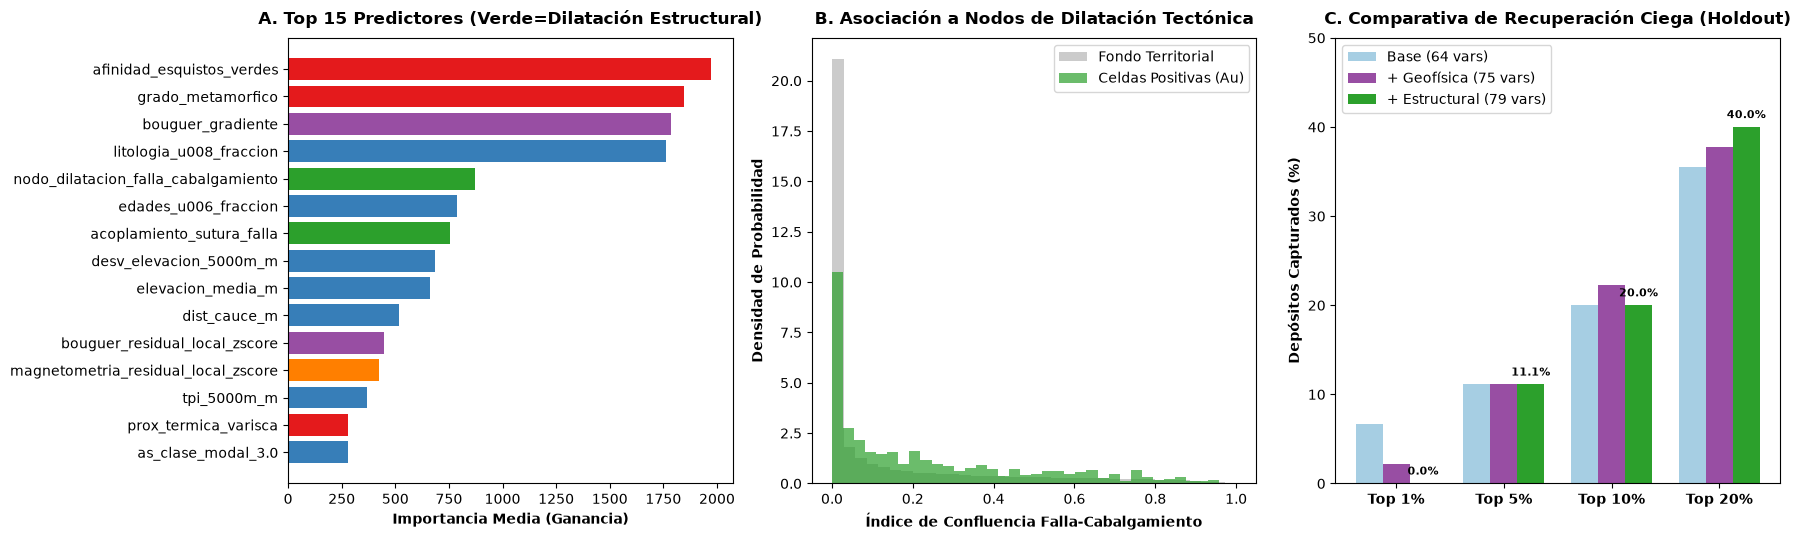

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), dpi=100)

# Panel 1: Top 15 Características
ax1 = axes[0]
top15 = df_imp.head(15).iloc[::-1]
col_map = {'Dilatación Estructural': '#2ca02c', 'Aeromagnetometría': '#ff7f00', 'Gravimetría': '#984ea3', 'Física Superficial': '#e41a1c', 'Original': '#377eb8'}
bar_colors = [col_map[t] for t in top15['tipo']]
ax1.barh(top15['feature'], top15['importance'], color=bar_colors)
ax1.set_xlabel('Importancia Media (Ganancia)', fontweight='bold')
ax1.set_title('A. Top 15 Predictores (Verde=Dilatación Estructural)', fontweight='bold', pad=10)

# Panel 2: Histograma del Nodo de Dilatación Estructural
ax2 = axes[1]
is_pos = X_all.index.isin(set(data.positives.cell_id))
ax2.hist(X_all.loc[~is_pos, 'nodo_dilatacion_falla_cabalgamiento'], bins=35, density=True, alpha=0.5, color='#999999', label='Fondo Territorial')
ax2.hist(X_all.loc[is_pos, 'nodo_dilatacion_falla_cabalgamiento'], bins=35, density=True, alpha=0.7, color='#2ca02c', label='Celdas Positivas (Au)')
ax2.set_xlabel('Índice de Confluencia Falla-Cabalgamiento', fontweight='bold')
ax2.set_ylabel('Densidad de Probabilidad', fontweight='bold')
ax2.set_title('B. Asociación a Nodos de Dilatación Tectónica', fontweight='bold', pad=10)
ax2.legend()

# Panel 3: Comparativa de Recuperación Ciega
ax3 = axes[2]
met_bars = ['Top 1%', 'Top 5%', 'Top 10%', 'Top 20%']
orig_bars = [3/45*100, 5/45*100, 9/45*100, 16/45*100]
grav_bars = [1/45*100, 5/45*100, 10/45*100, 17/45*100]
struct_bars = [summary_struct_rot['recovery_at_01']*100, summary_struct_rot['recovery_at_05']*100,
               summary_struct_rot['recovery_at_10']*100, summary_struct_rot['recovery_at_20']*100]

x = np.arange(len(met_bars))
w = 0.25
ax3.bar(x - w, orig_bars, width=w, label='Base (64 vars)', color='#a6cee3')
ax3.bar(x, grav_bars, width=w, label='+ Geofísica (75 vars)', color='#984ea3')
ax3.bar(x + w, struct_bars, width=w, label='+ Estructural (79 vars)', color='#2ca02c')
ax3.set_xticks(x)
ax3.set_xticklabels(met_bars, fontweight='bold')
ax3.set_ylabel('Depósitos Capturados (%)', fontweight='bold')
ax3.set_title('C. Comparativa de Recuperación Ciega (Holdout)', fontweight='bold', pad=10)
ax3.set_ylim(0, 50)
for i in range(len(x)):
    ax3.text(x[i] + w, struct_bars[i] + 1, f"{struct_bars[i]:.1f}%", ha='center', fontsize=8, fontweight='bold')
ax3.legend(loc='upper left')

plt.tight_layout()
plt.show()

In [8]:
out_dir = ROOT / "reports" / "reentrenamiento_estructuras_dilatacion_20261021"
out_dir.mkdir(parents=True, exist_ok=True)

df_export = pd.DataFrame({
    'cell_id': data.grid.cell_id.values,
    'favorabilidad_estructuras_dilatacion': score_ens,
    'dens_falla_1000m': X_all['dens_falla_1000m'].values,
    'nodo_dilatacion_falla_cabalgamiento': X_all['nodo_dilatacion_falla_cabalgamiento'].values,
    'trampa_dilatacional_reologica': X_all['trampa_dilatacional_reologica'].values,
    'acoplamiento_sutura_falla': X_all['acoplamiento_sutura_falla'].values
})
df_export.to_parquet(out_dir / "favorabilidad_nacional_estructuras_dilatacion.parquet", index=False)
df_comp_rot.to_csv(out_dir / "comparativa_evolucion_modelos.csv", index=False)
df_struct_stats.to_csv(out_dir / "estadisticas_trampas_dilatacion.csv", index=False)
df_imp.to_csv(out_dir / "importancia_variables_estructuras_dilatacion.csv", index=False)

print(f"✅ Artefactos del modelo con arquitectura de dilatación guardados en: {out_dir}")

✅ Artefactos del modelo con arquitectura de dilatación guardados en: C:\Users\Lenovo\Desktop\PROYECTO IA\GeoAI\GeoAI\reports\reentrenamiento_estructuras_dilatacion_20261021
